# Implied Moments from Options: BKM (2003)


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

---
## Data loading

All six data files are in the `data/` folder next to this notebook.

In [8]:
spx_ivs        = pd.read_parquet('data/spx_ivs_2023-02.parquet')#read spx_ivs_2023-02.parquet
sp500_ivs      = pd.read_parquet('data/sp500_merged_ivs_2023-02.parquet')#read sp500_merged_ivs_2023-02.parquet
implBeta_sp500 = pd.read_parquet('data/sp500_merged_implBeta_2023-02.parquet') #read sp500_merged_implBeta_2023-02.parquet
riskfree       = pd.read_csv('data/riskfree_30d_2023-02.csv')#read riskfree_30d_2023-02.csv

print('spx_ivs   :', spx_ivs.shape,   '  columns:', list(spx_ivs.columns))
print('sp500_ivs :', sp500_ivs.shape,  '  columns:', list(sp500_ivs.columns))
print('implBeta  :', implBeta_sp500.shape, '  columns:', list(implBeta_sp500.columns))
print('riskfree  :', riskfree.shape,   '  columns:', list(riskfree.columns))

spx_ivs   : (1083, 11)   columns: ['Symbol', 'loctimestamp', 'putcall', 'daystomaturity', 'implVol', 'implPrice', 'strike', 'forwardMoneyness', 'normalizedMoneyness', 'underlyingprice', 'underlyingforwardprice']
sp500_ivs : (539847, 11)   columns: ['Symbol', 'loctimestamp', 'putcall', 'daystomaturity', 'implVol', 'implPrice', 'strike', 'forwardMoneyness', 'normalizedMoneyness', 'underlyingprice', 'underlyingforwardprice']
implBeta  : (9471, 4)   columns: ['Symbol', 'loctimestamp', 'daystomaturity', 'implBeta']
riskfree  : (19, 3)   columns: ['date', 'daystomaturity', 'yld_pct_annual']


In [9]:
def compute_contract_prices(group):
    """
    Compute BKM (2003) contract prices V, W, X for one
    (Symbol, loctimestamp, daystomaturity) group.

    Parameters
    ----------
    group : pd.DataFrame
        Rows for one group (OTM puts and calls).
        Key columns: 'strike', 'implPrice', 'underlyingprice'.

    Returns
    -------
    pd.Series with keys 'V_t_tau', 'W_t_tau', 'X_t_tau'.
    """
    # 1. Extract the spot price S_t (constant within the group).
    S = group['underlyingprice'].iloc[0]

    # 2. Sort by strike
    g = group.sort_values('strike')
    K = g['strike'].to_numpy(dtype=float)
    O = g['implPrice'].to_numpy(dtype=float)

    # 3. Build integrand arrays (put vs call by moneyness)
    is_put  = K < S
    is_call = K > S

    lnSK = np.log(S / K)
    lnKS = np.log(K / S)

    iV = np.zeros_like(K)
    iW = np.zeros_like(K)
    iX = np.zeros_like(K)

    # For OTM puts  (K < S_t)
    iV[is_put] = 2 * (1 + lnSK[is_put]) / K[is_put]**2 * O[is_put]
    iW[is_put] = -(6 * lnSK[is_put] + 3 * lnSK[is_put]**2) / K[is_put]**2 * O[is_put]
    iX[is_put] = (12 * lnSK[is_put]**2 + 4 * lnSK[is_put]**3) / K[is_put]**2 * O[is_put]

    # For OTM calls (K > S_t)
    iV[is_call] = 2 * (1 - lnKS[is_call]) / K[is_call]**2 * O[is_call]
    iW[is_call] = (6 * lnKS[is_call] - 3 * lnKS[is_call]**2) / K[is_call]**2 * O[is_call]
    iX[is_call] = (12 * lnKS[is_call]**2 - 4 * lnKS[is_call]**3) / K[is_call]**2 * O[is_call]

    # 4. Integrate each array over K with np.trapzoid
    V = np.trapezoid(iV, K)
    W = np.trapezoid(iW, K)
    X = np.trapezoid(iX, K)

    # 5. Return Series({'V_t_tau': ..., 'W_t_tau': ..., 'X_t_tau': ...}).
    return pd.Series({'V_t_tau': V, 'W_t_tau': W, 'X_t_tau': X})

In [10]:
contract_prices = (
    spx_ivs
    .groupby(["Symbol", "loctimestamp", "daystomaturity"])
    .apply(compute_contract_prices, include_groups=False)
    .reset_index()
)

print(contract_prices.shape)
contract_prices.head()

AttributeError: module 'numpy' has no attribute 'trapezoid'

In [ ]:
contract_prices_sp500 = (
    sp500_ivs
    .groupby(["Symbol", "loctimestamp", "daystomaturity"])
    .apply(compute_contract_prices, include_groups=False)
    .reset_index()
)

print(contract_prices_sp500.shape)
contract_prices_sp500.head()

AttributeError: module 'numpy' has no attribute 'trapezoid'


## BKM Implied Moments μ, σ², SKEW, KURT  

In [ ]:


riskfree['exp_rt'] = np.exp(riskfree['yld_pct_annual'] / 100
  * riskfree['daystomaturity'] / 365)
riskfree.head()

,date,daystomaturity,yld_pct_annual,exp_rt
0,2023-02-01,30,4.680,1.003854
1,2023-02-02,30,4.714,1.003882
2,2023-02-03,30,4.629,1.003812
3,2023-02-06,30,4.686,1.003859
4,2023-02-07,30,4.685,1.003858


In [ ]:

# Steps:
#   1. Merge contract_prices with riskfree.
#      Match: loctimestamp <-> date   AND   daystomaturity <-> daystomaturity.
riskfree['date'] = pd.to_datetime(riskfree['date'])
df = contract_prices.merge(
      riskfree,
      left_on=['loctimestamp', 'daystomaturity'],
      right_on=['date', 'daystomaturity'],
  )


#   2. Compute the five moment columns using the formulas from the README.
#      (bakshi_mu, bakshi_implVar, bakshi_implVol_annual, bakshi_skew, bakshi_kurt)
exp_rt = df['exp_rt']
V = df['V_t_tau']
W = df['W_t_tau']
X = df['X_t_tau']

mu   = exp_rt - 1 - (exp_rt/2)*V - (exp_rt/6)*W - (exp_rt/24)*X
var  = exp_rt * V - mu**2
SKEW = (exp_rt*W - 3*mu*var + 2*mu**3) / var**(3/2)
KURT = (exp_rt*X - 4*mu*exp_rt*W + 6*mu**3*var - 3*mu**4) / var**2

df['bakshi_mu'] = mu
df['bakshi_implVar'] = var
df['bakshi_implVol_annual'] = np.sqrt(var)
df['bakshi_skew'] = SKEW
df['bakshi_kurt'] = KURT

#   3. Keep only the required columns.
#
# Required output variable : bakshi_moments_spx
# Required columns         : Symbol, loctimestamp, daystomaturity,
#                            bakshi_mu, bakshi_implVar, bakshi_implVol_annual,
#                            bakshi_skew, bakshi_kurt
# Expected shape           : (19, 8)

bakshi_moments_spx = df[[
      'Symbol', 'loctimestamp', 'daystomaturity',
      'bakshi_mu', 'bakshi_implVar', 'bakshi_implVol_annual',
      'bakshi_skew', 'bakshi_kurt',
  ]]

print(bakshi_moments_spx.shape)
bakshi_moments_spx

(19, 8)


,Symbol,loctimestamp,daystomaturity,bakshi_mu,bakshi_implVar,bakshi_implVol_annual,bakshi_skew,bakshi_kurt
0,^SPX,2023-02-01,30,0.002449,0.002886,0.053724,-1.913569,13.694993
1,^SPX,2023-02-02,30,0.002274,0.003315,0.057578,-1.947115,14.016686
2,^SPX,2023-02-03,30,0.002444,0.002812,0.053024,-1.983594,14.077755
3,^SPX,2023-02-06,30,0.002251,0.003310,0.057532,-1.883174,13.439291
4,^SPX,2023-02-07,30,0.002434,0.002927,0.054100,-1.939267,14.260861
5,^SPX,2023-02-08,30,0.002297,0.003261,0.057103,-1.984725,14.250990
6,^SPX,2023-02-09,30,0.002096,0.003718,0.060976,-1.964249,13.935636
7,^SPX,2023-02-10,30,0.002207,0.003433,0.058594,-1.973603,14.298707
8,^SPX,2023-02-13,30,0.002036,0.003885,0.062332,-1.886176,13.734386
9,^SPX,2023-02-14,30,0.002452,0.002883,0.053695,-1.990065,14.378496


In [ ]:

# Required output variable : bakshi_moments_sp500
# Steps:
#   1. Merge contract_prices with riskfree.
#      Match: loctimestamp <-> date   AND   daystomaturity <-> daystomaturity.
riskfree['date'] = pd.to_datetime(riskfree['date'])
df = contract_prices_sp500.merge(
      riskfree,
      left_on=['loctimestamp', 'daystomaturity'],
      right_on=['date', 'daystomaturity'],
  )


#   2. Compute the five moment columns using the formulas from the README.
#      (bakshi_mu, bakshi_implVar, bakshi_implVol_annual, bakshi_skew, bakshi_kurt)
exp_rt = df['exp_rt']
V = df['V_t_tau']
W = df['W_t_tau']
X = df['X_t_tau']

mu   = exp_rt - 1 - (exp_rt/2)*V - (exp_rt/6)*W - (exp_rt/24)*X
var  = exp_rt * V - mu**2
SKEW = (exp_rt*W - 3*mu*var + 2*mu**3) / var**(3/2)
KURT = (exp_rt*X - 4*mu*exp_rt*W + 6*mu**3*var - 3*mu**4) / var**2

df['bakshi_mu'] = mu
df['bakshi_implVar'] = var
df['bakshi_implVol_annual'] = np.sqrt(var)
df['bakshi_skew'] = SKEW
df['bakshi_kurt'] = KURT

#   3. Keep only the required columns.
#
# Required output variable : bakshi_moments_spx
# Required columns         : Symbol, loctimestamp, daystomaturity,
#                            bakshi_mu, bakshi_implVar, bakshi_implVol_annual,
#                            bakshi_skew, bakshi_kurt
# Expected shape           : (~9471, 8)

bakshi_moments_sp500 = df[[
      'Symbol', 'loctimestamp', 'daystomaturity',
      'bakshi_mu', 'bakshi_implVar', 'bakshi_implVol_annual',
      'bakshi_skew', 'bakshi_kurt',
  ]]

print(bakshi_moments_sp500.shape)
bakshi_moments_sp500.head()

(9471, 8)


/Users/flo/Documents/Uni/FDS/FDS_py/PS3/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Symbol,loctimestamp,daystomaturity,bakshi_mu,bakshi_implVar,bakshi_implVol_annual,bakshi_skew,bakshi_kurt
0,A,2023-02-01,30,-0.000401,0.008679,0.093162,-0.757728,5.984690
1,A,2023-02-02,30,-0.000566,0.009093,0.095357,-0.798771,5.606309
2,A,2023-02-03,30,-0.000476,0.008788,0.093745,-0.899281,6.096325
3,A,2023-02-06,30,-0.000730,0.009396,0.096933,-0.839692,5.810152
4,A,2023-02-07,30,-0.000662,0.009375,0.096824,-1.266905,7.296563


---
## Task 2 — Skewness Decomposition: Systematic and Idiosyncratic   *(3.0 pts)*

Under the CAPM the return of stock *i* is
$R_i = \alpha_i + \beta_i R_m + \varepsilon_i$.
By **cumulant additivity** between independent random variables:

$$\kappa_n(R_i) = \kappa_n(\alpha_i + \beta_i R_m) + \kappa_n(\varepsilon_i), \qquad
\kappa_n(\alpha_i + \beta_i R_m) = \beta_i^n \kappa_n(R_m) \text{ for } n > 1.$$

Because the **third cumulant equals the third central moment** and
**SKEW is the third standardised moment**, we have
$\kappa_3 = \text{SKEW} \times (\sigma^2)^{3/2}$,
which allows a clean decomposition into systematic and idiosyncratic parts.

All step-by-step formulas are in the README *Skewness decomposition* section.

**Required output — a DataFrame named `merged_decomposition_df`** containing
(among other columns):

| Column | Description |
|--------|-------------|
| `bakshi_skew` | total implied skewness of stock *i* |
| `bakshi_skew_sys` | systematic skewness (β³ channel) |
| `bakshi_skew_eps` | idiosyncratic skewness |

plus identifiers `Symbol`, `loctimestamp`, `daystomaturity`.

> **Hint:** You need two merges before computing the formulas:
> (1) join `bakshi_moments_sp500` with `implBeta_sp500` on
> `['Symbol', 'loctimestamp', 'daystomaturity']`;
> (2) bring in the SPX implied variance and skew from `bakshi_moments_spx`
> matching on `['loctimestamp', 'daystomaturity']`.

In [ ]:

# Steps (all formulas in README 'Skewness decomposition' section):
#   1. Merge bakshi_moments_sp500 with implBeta_sp500
#      on ['Symbol', 'loctimestamp', 'daystomaturity'].
merged_decomposition_df = bakshi_moments_sp500.merge(
      implBeta_sp500,
      on=['Symbol', 'loctimestamp',
  'daystomaturity'],
  )

#   2. Merge result with bakshi_moments_spx (SPX var and skew)
#      on ['loctimestamp', 'daystomaturity'].
merged_decomposition_df = merged_decomposition_df.merge(
      bakshi_moments_spx[['loctimestamp',
  'daystomaturity', 'bakshi_implVar',
  'bakshi_skew']],
      on=['loctimestamp', 'daystomaturity'],
      suffixes=('', '_spx'),
  )


#   3. Third cumulants:
bakshi_k3_SPX = merged_decomposition_df['bakshi_skew_spx'] * merged_decomposition_df['bakshi_implVar_spx'] ** 1.5
bakshi_k3     = merged_decomposition_df['bakshi_skew'] * merged_decomposition_df['bakshi_implVar'] ** 1.5
#   4. Decompose:
bakshi_k3_sys = merged_decomposition_df['implBeta']**3 * bakshi_k3_SPX
bakshi_k3_eps = bakshi_k3 - bakshi_k3_sys
#   5. Standardise:
bakshi_skew_sys = bakshi_k3_sys / merged_decomposition_df['bakshi_implVar']**(3/2)
bakshi_skew_eps = bakshi_k3_eps / merged_decomposition_df['bakshi_implVar']**(3/2)

#add remaining parameters to merged_decomposition_df
merged_decomposition_df['bakshi_skew_sys'] = bakshi_skew_sys
merged_decomposition_df['bakshi_skew_eps'] = bakshi_skew_eps

# Sanity check: bakshi_skew_sys + bakshi_skew_eps should equal bakshi_skew.
#print(bakshi_skew_sys + bakshi_skew_eps)
#print("----------------")
#print(merged_decomposition_df['bakshi_skew'])


# Required output variable : merged_decomposition_df
# Expected shape           : (~9471 rows)

merged_decomposition_df = merged_decomposition_df

print(merged_decomposition_df.shape)
merged_decomposition_df[
    ['Symbol', 'loctimestamp', 'daystomaturity',
     'bakshi_skew', 'bakshi_skew_sys', 'bakshi_skew_eps']
].head(10)

(9471, 13)


,Symbol,loctimestamp,daystomaturity,bakshi_skew,bakshi_skew_sys,bakshi_skew_eps
0,A,2023-02-01,30,-0.757728,-0.008648,-0.749079
1,A,2023-02-02,30,-0.798771,-0.001794,-0.796977
2,A,2023-02-03,30,-0.899281,-0.019565,-0.879716
3,A,2023-02-06,30,-0.839692,-0.025727,-0.813966
4,A,2023-02-07,30,-1.266905,-0.090274,-1.176632
5,A,2023-02-08,30,-1.316317,-0.009003,-1.307315
6,A,2023-02-09,30,-1.047887,-0.001893,-1.045993
7,A,2023-02-10,30,-0.558790,-0.000101,-0.558689
8,A,2023-02-13,30,-1.919333,-0.022944,-1.896389
9,A,2023-02-14,30,-1.237708,-0.247283,-0.990425


---
## Index vs. Single-Stock Skewness  

BKM (2003) show in **Table 6** that the implied skewness of the index is more
pronounced (more negative) than the implied skewness of individual stocks.

**3a — Cross-sectional comparison metric**

For each S&P 500 constituent compute two statistics across the 19 trading days
of February 2023:

- `Percentage_Skew_less_than_0` — % of days on which `bakshi_skew` is negative.
- `Percentage_Skew_more_than_SPX` — % of days on which `bakshi_skew` is
  **greater than** (less negative than) the SPX `bakshi_skew` on the same day.

Implement `calculate_skew_metrics(df)` below and apply it with
`groupby('Symbol')` to produce **`skew_test`** with columns
`Symbol`, `Percentage_Skew_less_than_0`, `Percentage_Skew_more_than_SPX`.

**3b — Visualisation**

Create at least one matplotlib/seaborn figure illustrating the difference
between index-level and single-stock implied skewness. End with `plt.show()`.

**3c — Economic interpretation** — write your answer in the markdown cell below.

> **Hint:** Before applying `calculate_skew_metrics`, merge
> `bakshi_moments_sp500` with the daily SPX skew from `bakshi_moments_spx`
> on `loctimestamp` so that each stock-day row carries the matching index skew.

In [ ]:
def calculate_skew_metrics(df):
    """
    Compute cross-sectional skewness statistics for one stock (one Symbol group).

    Parameters
    ----------
    df : pd.DataFrame
        Rows for a single stock across all trading days.
        Must contain 'bakshi_skew' (stock) and 'bakshi_skew_spx' (index, same day).

    Returns
    -------
    pd.Series with keys:
        'Percentage_Skew_less_than_0'   -- % of days where bakshi_skew < 0
        'Percentage_Skew_more_than_SPX' -- % of days where bakshi_skew > bakshi_skew_spx
    """
    return pd.Series({
          'Percentage_Skew_less_than_0':   100 * (df['bakshi_skew'] < 0).mean(),
          'Percentage_Skew_more_than_SPX': 100 * (df['bakshi_skew'] > df['bakshi_skew_spx']).mean(),
      })


In [ ]:
# Steps:
#   1. Rename bakshi_skew in bakshi_moments_spx to 'bakshi_skew_spx' and
#      merge it into bakshi_moments_sp500 matching on 'loctimestamp'.
spx_skew = bakshi_moments_spx[['loctimestamp',
  'bakshi_skew']].rename(
      columns={'bakshi_skew':
  'bakshi_skew_spx'})

merged = bakshi_moments_sp500.merge(spx_skew, on='loctimestamp')

#   2. Apply calculate_skew_metrics via groupby('Symbol').
#      (See README 'Recommended function' for the groupby.apply pattern.)
# Required output variable : skew_test
# Required columns         : Symbol,
#                            Percentage_Skew_less_than_0,
#                            Percentage_Skew_more_than_SPX
# Expected shape           : (500, 3)

skew_test = (
      merged
      .groupby('Symbol')
      .apply(calculate_skew_metrics,
  include_groups=False)
      .reset_index()
  )

print(skew_test.shape)
skew_test.head()

(500, 3)


,Symbol,Percentage_Skew_less_than_0,Percentage_Skew_more_than_SPX
0,A,100.0,89.473684
1,AAL,100.0,100.000000
2,AAP,100.0,100.000000
3,AAPL,100.0,100.000000
4,ABBV,100.0,100.000000


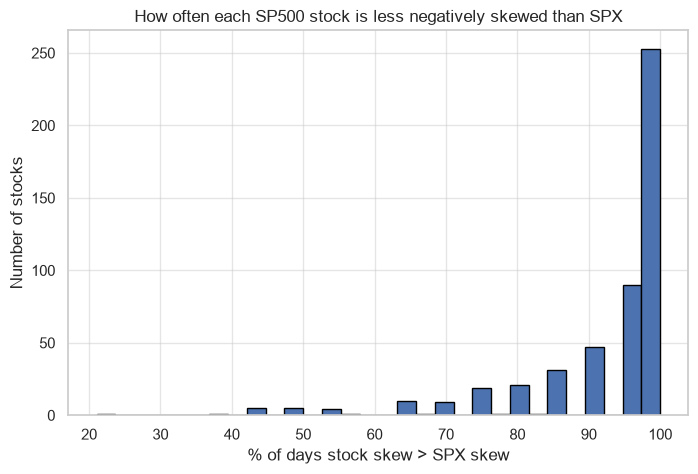

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(skew_test['Percentage_Skew_more_than_SPX'], bins=30, edgecolor='black')
ax.set_xlabel('% of days stock skew > SPX skew')
ax.set_ylabel('Number of stocks')
ax.set_title('How often each SP500 stock is less negatively skewed than SPX')
plt.show()